# 02 — Exploratory Data Analysis

Explore sales distribution, branch and category performance, monthly trends, and customer segmentation.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

base_url = "https://raw.githubusercontent.com/naisoisharonkarinoh/plp-capstone-a-sharon-koina/main/"

sales = pd.read_csv(base_url + "data/processed/sales_clean.csv", parse_dates=['date'])
products = pd.read_csv(base_url + "data/raw/products.csv")
customers = pd.read_csv(base_url + "data/raw/customers.csv")

print("Sales:", sales.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
df = sales.merge(products, on='product_id').merge(customers, on='customer_id')
df.head()

Sales: (5000, 11)
Products: (20, 4)
Customers: (1000, 3)


,transaction_id,date,branch,customer_id,product_id,quantity,discount_rate,gross_sales_kes,discount_kes,net_sales_kes,month,product_name,category,unit_price_kes,customer_segment,county
0,T00001,2025-02-02,Nairobi,C0717,P013,1,0.05,390,19.5,370.5,2025-02,Shampoo 400ml,Personal Care,390,Regular,Uasin Gishu
1,T00002,2025-10-10,Nairobi,C0539,P007,1,0.00,65,0.0,65.0,2025-10,Bread,Bakery,65,Regular,Kisumu
2,T00003,2025-08-27,Nairobi,C0162,P009,2,0.00,680,0.0,680.0,2025-08,Coffee 100g,Beverages,340,Regular,Kiambu
3,T00004,2025-06-10,Kisumu,C0930,P004,1,0.00,180,0.0,180.0,2025-06,Maize Flour 2kg,Grocery,180,Loyal,Kisumu
4,T00005,2025-06-08,Nakuru,C0251,P013,1,0.00,390,0.0,390.0,2025-06,Shampoo 400ml,Personal Care,390,Regular,Kisumu


## Univariate analysis — transaction values

In [ ]:
df['net_sales_kes'].describe()

In [ ]:
df['net_sales_kes'].hist(bins=30)
plt.title('Distribution of transaction net sales')
plt.xlabel('Net sales (KES)')
plt.ylabel('Frequency')
plt.show()

## Bivariate analysis — branch and category

In [ ]:
branch_sales = df.groupby('branch')['net_sales_kes'].sum().sort_values(ascending=False)
branch_sales.plot(kind='bar', title='Net sales by branch', ylabel='KES', rot=30)
plt.show()
category_sales = df.groupby('category')['net_sales_kes'].sum().sort_values(ascending=False)
category_sales.plot(kind='barh', title='Net sales by category', xlabel='KES')
plt.show()

## Segmentation — customer groups

In [ ]:
segment_sales = df.groupby('customer_segment').agg(customers=('customer_id','nunique'), revenue_kes=('net_sales_kes','sum'), transactions=('transaction_id','count'))
segment_sales

In [4]:
df = sales.copy()
# RFM Customer Segmentation

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Set analysis date
snapshot_date = df['date'].max() + pd.Timedelta(days=1)

# Calculate Recency, Frequency and Monetary value
rfm = df.groupby('customer_id').agg(
    recency=('date', lambda x: (snapshot_date - x.max()).days),
    frequency=('transaction_id', 'nunique'),
    monetary=('net_sales_kes', 'sum')
).reset_index()

# Score customers from 1 to 4
rfm['R_score'] = pd.qcut(
    rfm['recency'].rank(method='first'),
    4, labels=[4, 3, 2, 1]
).astype(int)

rfm['F_score'] = pd.qcut(
    rfm['frequency'].rank(method='first'),
    4, labels=[1, 2, 3, 4]
).astype(int)

rfm['M_score'] = pd.qcut(
    rfm['monetary'].rank(method='first'),
    4, labels=[1, 2, 3, 4]
).astype(int)

# Combine RFM scores
rfm['RFM_score'] = (
    rfm['R_score'].astype(str) +
    rfm['F_score'].astype(str) +
    rfm['M_score'].astype(str)
)

# Assign customer segments
def assign_segment(row):
    if row['R_score'] >= 3 and row['F_score'] >= 3 and row['M_score'] >= 3:
        return 'Champions'
    elif row['R_score'] >= 3 and row['F_score'] >= 2:
        return 'Loyal Customers'
    elif row['R_score'] <= 2 and row['F_score'] >= 2:
        return 'At Risk'
    else:
        return 'Other Customers'

rfm['customer_segment'] = rfm.apply(assign_segment, axis=1)

# Display customer segments
rfm.head(10)

,customer_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,customer_segment
0,C0001,11,2,761.0,4,1,1,411,Other Customers
1,C0002,48,9,2833.1,3,4,3,343,Champions
2,C0003,96,3,1978.8,2,1,2,212,Other Customers
3,C0004,108,3,1203.6,1,1,1,111,Other Customers
4,C0005,80,4,6927.6,2,2,4,224,At Risk
5,C0006,1,7,3958.8,4,4,3,443,Champions
6,C0007,84,4,584.0,2,2,1,221,At Risk
7,C0008,75,3,2645.0,2,1,3,213,Other Customers
8,C0009,174,4,5209.0,1,2,4,124,At Risk
9,C0010,121,2,6730.0,1,1,4,114,Other Customers


,date,net_sales_kes
0,2025-01-01,259408.70
1,2025-02-01,315530.60
2,2025-03-01,276600.70
3,2025-04-01,257112.55
4,2025-05-01,266647.70
5,2025-06-01,274731.95
6,2025-07-01,286649.00
7,2025-08-01,287133.70
8,2025-09-01,232739.95
9,2025-10-01,279284.35


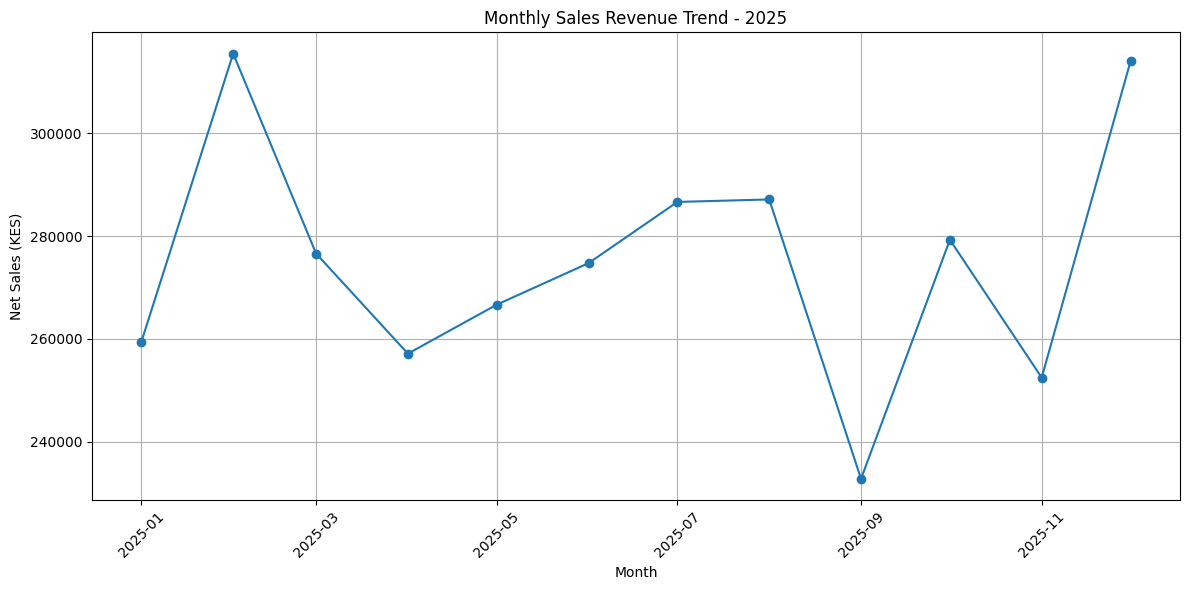

In [5]:
# Monthly Sales Trend Analysis

# Group sales by month
monthly_sales = (
    sales.groupby(sales['date'].dt.to_period('M'))['net_sales_kes']
    .sum()
    .reset_index()
)

# Convert month to date format
monthly_sales['date'] = monthly_sales['date'].dt.to_timestamp()

# Display monthly revenue
display(monthly_sales)

# Plot monthly revenue trend
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_sales['date'],
    monthly_sales['net_sales_kes'],
    marker='o'
)

plt.title('Monthly Sales Revenue Trend - 2025')
plt.xlabel('Month')
plt.ylabel('Net Sales (KES)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()